### <center>**linear regression: Paractice**<center/>

In [54]:
# 
import pandas as pd 
import numpy as np
# vizualization 
import matplotlib.pyplot as plt
import seaborn as sns
# sklearn
from sklearn import linear_model 
from sklearn import metrics
from sklearn import preprocessing
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split

### Load data

In [55]:
abop_original = pd.read_csv('data/insurance.csv')
abop = abop_original.copy(deep=True)
display(abop.head())
abop.info()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [56]:
print(abop.shape)
display(abop.isnull().sum())
display(abop.dtypes)

(1338, 7)


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

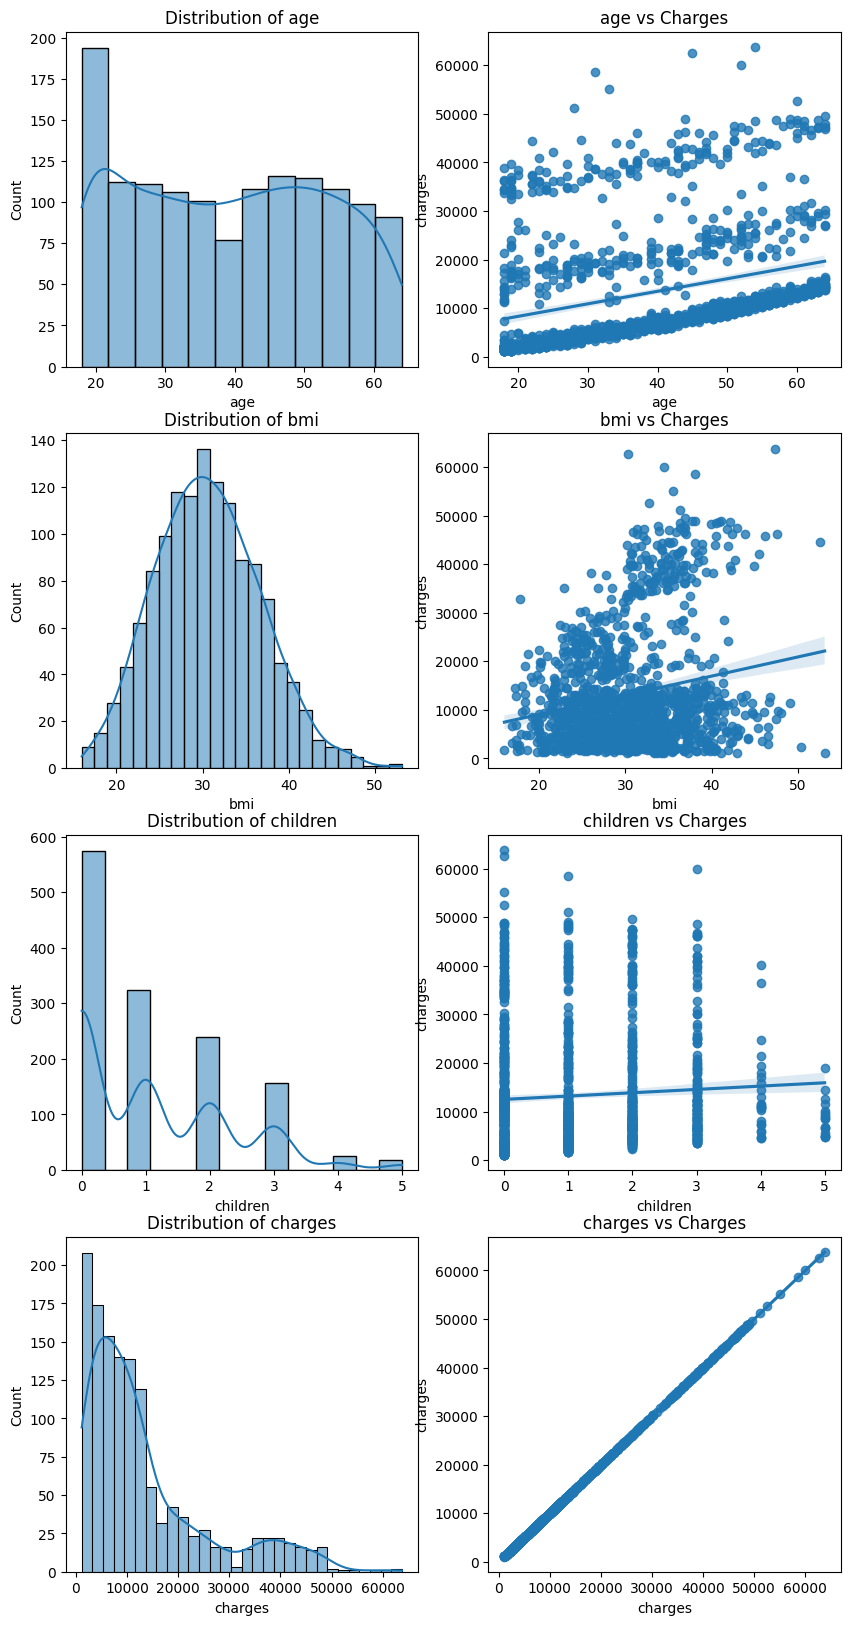

In [57]:
num_features = list(abop.select_dtypes(include=[int, float]).columns)
cat_features = list(abop.select_dtypes(include=[object, str]).columns)

fig, axes = plt.subplots(nrows=len(num_features), ncols=2, figsize=(10, 5*len(num_features)))
for i, feature in enumerate(num_features):
    sns.histplot(data=abop, x=feature, ax=axes[i][0], kde=True)
    axes[i][0].set_title(f'Distribution of {feature}')
    sns.regplot(data=abop, x=feature, y='charges', ax=axes[i][1])
    axes[i][1].set_title(f'{feature} vs Charges')   


<Axes: >

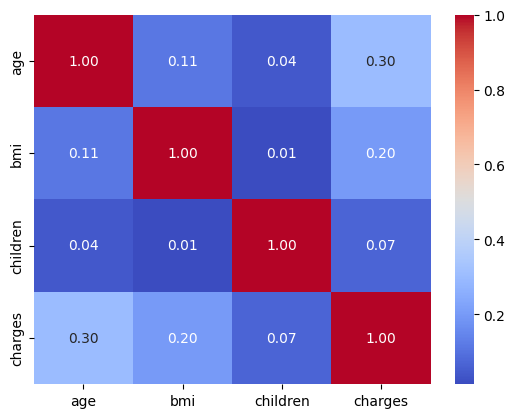

In [58]:
sns.heatmap(abop[num_features].corr(), annot=True, cmap='coolwarm', fmt='.2f')

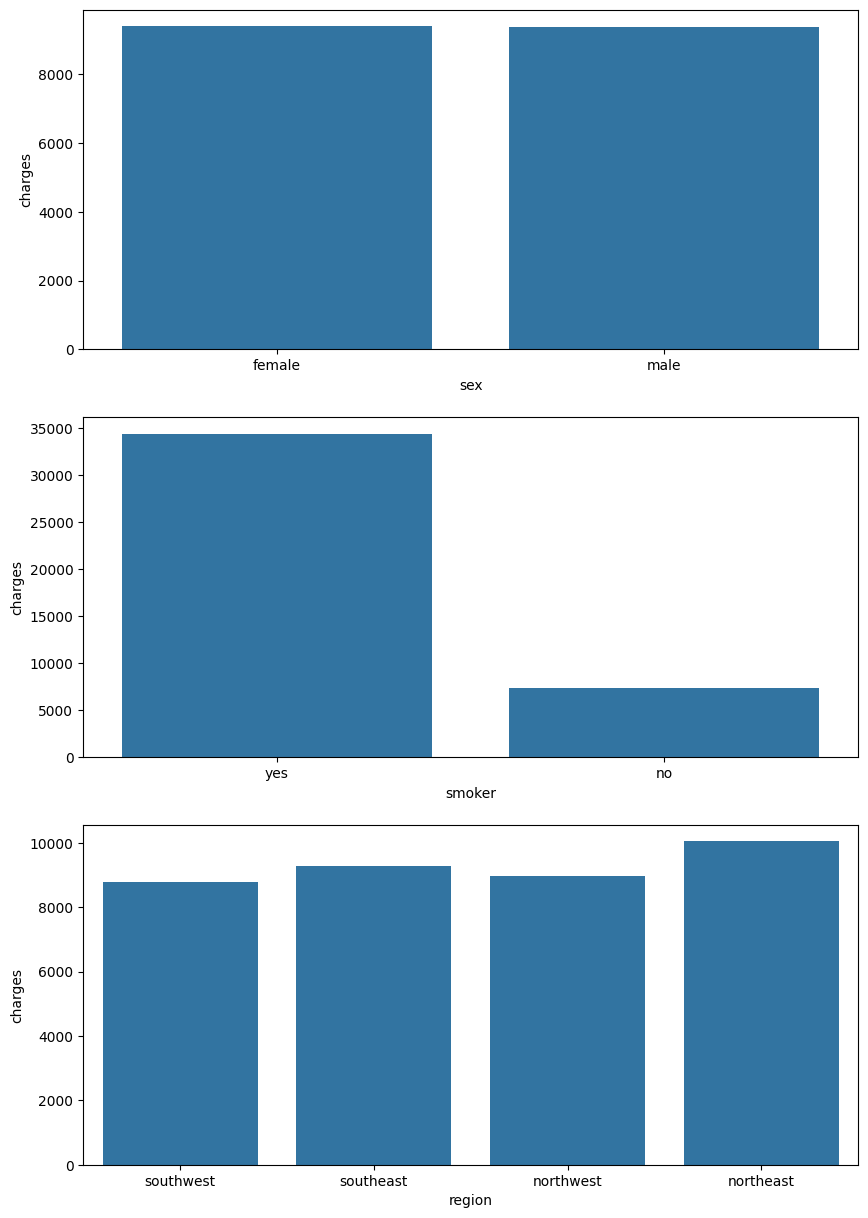

In [59]:
fig, axes = plt.subplots(nrows=len(cat_features), ncols=1, figsize=(10, 5*len(cat_features)))
for i, feature in enumerate(cat_features):
    sns.barplot(
        data=abop,
        x=feature,
        y='charges',
        estimator=np.median,
        errorbar=None,
        ax=axes[i]
    )

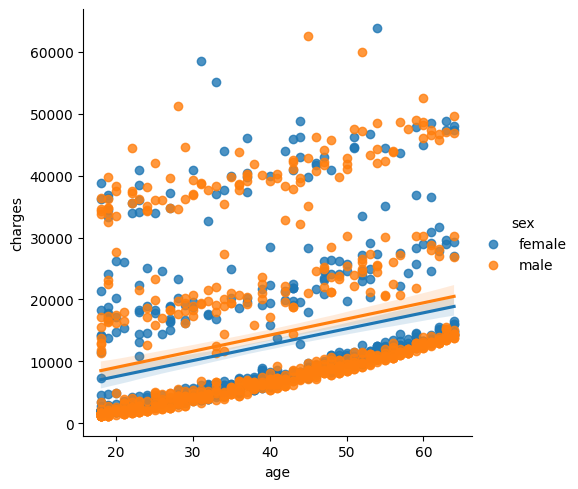

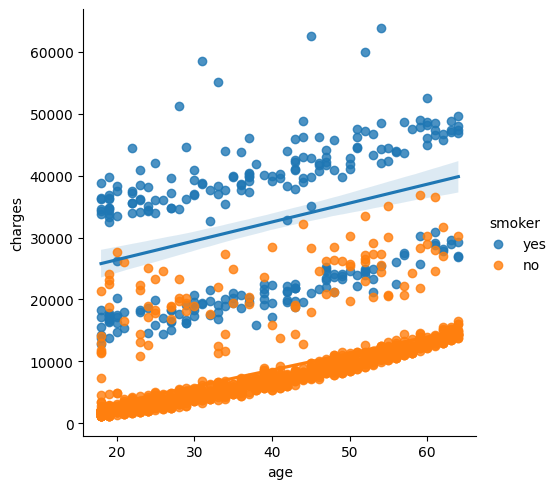

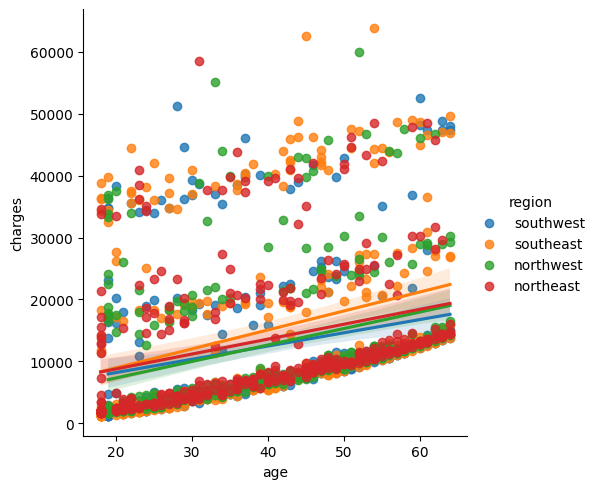

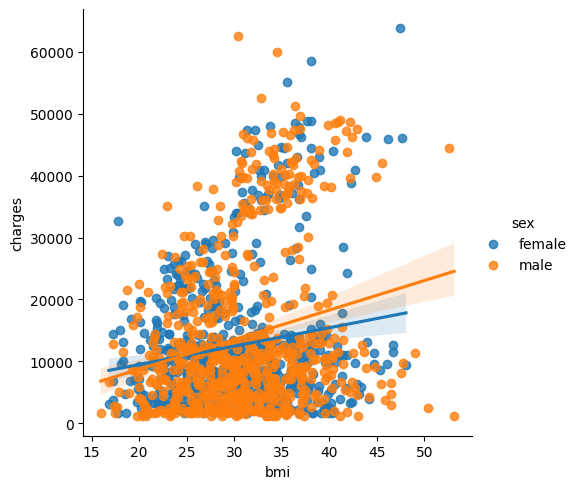

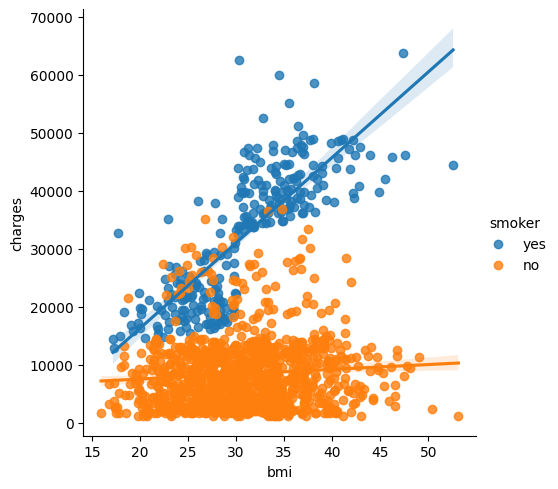

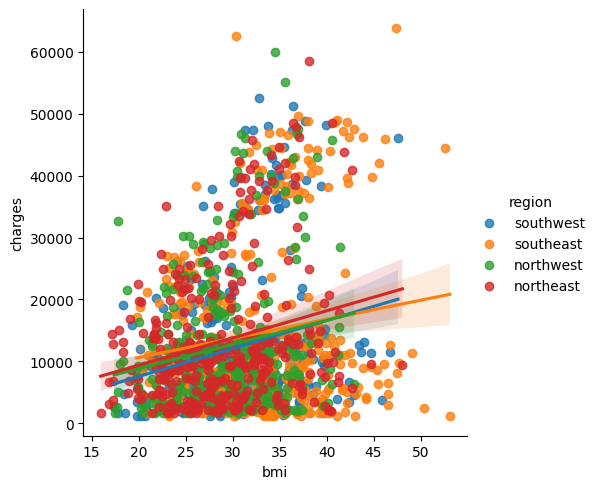

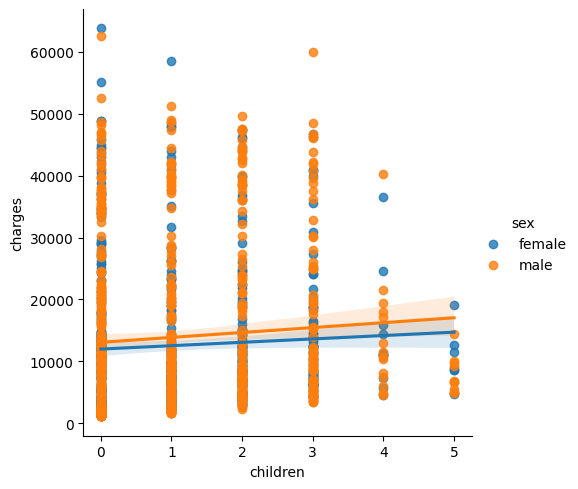

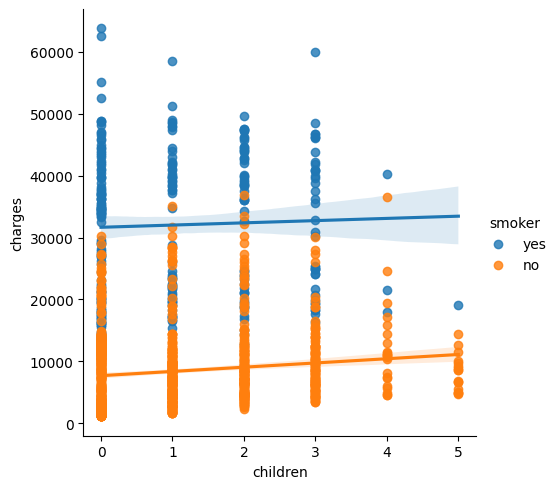

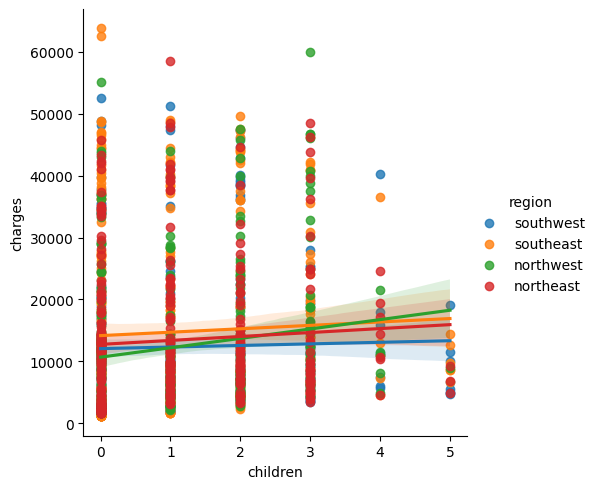

In [60]:
num_no_charges = num_features.copy()
num_no_charges.remove('charges')
for num in num_no_charges:
    for cat in cat_features:
        sns.lmplot(
            data=abop,
            x=num,
            y='charges',
            hue=cat
        )

In [61]:
abop['smoker'] = abop['smoker'].apply(lambda x: 0 if x == 'no' else 1)
abop['sex'] = abop['sex'].apply(lambda x: 0 if x == 'female' else 1)
abop = pd.get_dummies(abop)
abop.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,False,False,False,True
1,18,1,33.770,1,0,1725.55230,False,False,True,False
2,28,1,33.000,3,0,4449.46200,False,False,True,False
3,33,1,22.705,0,0,21984.47061,False,True,False,False
4,32,1,28.880,0,0,3866.85520,False,True,False,False


### <center>**МОДЕЛИРОВАНИЕ**

In [62]:
def print_metricks(y_train, y_train_pred, y_test, y_test_pred):
    print('Train R^2:', round(metrics.r2_score(y_train, y_train_pred), 3))
    print('Train MAE:', round(metrics.mean_absolute_error(y_train, y_train_pred), 3))
    print('Train MAPE:', round(metrics.mean_absolute_percentage_error(y_train, y_train_pred)*100, 3))
    print('\n')
    print('Test R^2:', round(metrics.r2_score(y_test, y_test_pred), 3))
    print('Test MAE:', round(metrics.mean_absolute_error(y_test, y_test_pred), 3))
    print('Test MAPE:', round(metrics.mean_absolute_percentage_error(y_test, y_test_pred)*100, 3))

In [63]:
# split the data into train and test sets
X = abop.drop(columns=['charges'])
y = abop['charges']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#### обучение аналитический метод

In [64]:
lr_model = linear_model.LinearRegression()
lr_model.fit(X_train, y_train) 
#
print('Intercept:', round(lr_model.intercept_, 3))

Intercept: -12390.804


In [65]:
lr_train_predict = lr_model.predict(X_train)
lr_test_predict = lr_model.predict(X_test)
print_metricks(y_train, lr_train_predict, y_test, lr_test_predict)

Train R^2: 0.742
Train MAE: 4208.235
Train MAPE: 42.203


Test R^2: 0.784
Test MAE: 4181.194
Test MAPE: 46.888


Text(0.5, 1.0, 'Test Error Distribution')

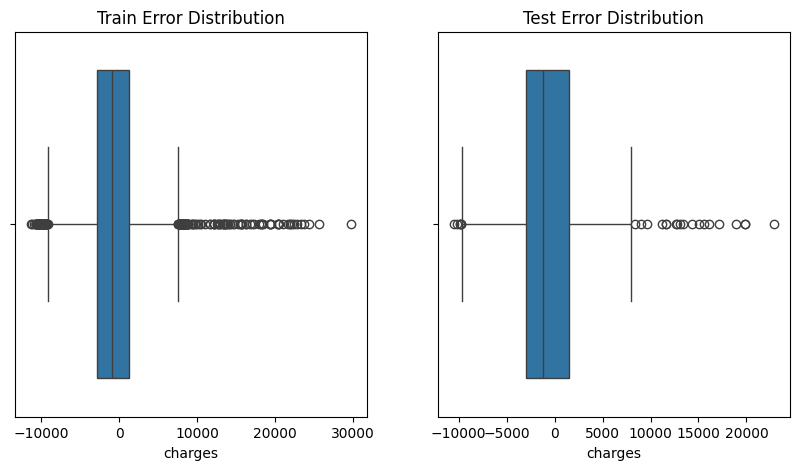

In [66]:
err_test = y_test - lr_test_predict
err_train = y_train - lr_train_predict
#
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
boxplot_0 = sns.boxplot(
    data=err_train,
    orient='h',
    ax=axes[0]
)
boxplot_0.set_title('Train Error Distribution')

boxplot_1 = sns.boxplot(
    data=err_test,
    orient='h',
    ax=axes[1]
)
boxplot_1.set_title('Test Error Distribution')


### <center>**НОРМАЛИЗАЦИЯ ДАННЫХ**

In [93]:
# нормализация
scaler = preprocessing.MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)
# полиномиальные признаки
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.fit_transform(X_test_scaled)

In [98]:
# обучение модели линейной регрессии на полиномиальных признаках
lr_poly_model = linear_model.LinearRegression()
lr_poly_model.fit(X_train_poly, y_train)
# прогнозирование на обучающей и тестовой выборках
lr_poly_train_predict = lr_poly_model.predict(X_train_poly)
lr_poly_test_predict = lr_poly_model.predict(X_test_poly)
print_metricks(y_train, lr_poly_train_predict, y_test, lr_poly_test_predict)

Train R^2: 0.842
Train MAE: 2892.15
Train MAPE: 29.399


Test R^2: 0.866
Test MAE: 2694.092
Test MAPE: 29.752


In [99]:
print(lr_poly_model.coef_)

[ 2849.35067435  -417.24034999  5935.92169643  4636.08544526
  1139.1491985    351.86496094  -366.48563336   227.08922666
  -212.46855424  8399.63608632   812.46558472   995.68651894
 -1666.91118191   172.50303109  -848.02252419   280.84325571
  1455.92298005  1960.60696278  -417.24034999   647.47475622
 -1238.19812114   257.33745404  -966.67881613   311.8232212
   544.21466602  -306.59942109 -9711.00034091  1559.87212018
 54839.212545    3782.01457236  2765.86075737  -794.72610916
   182.77247586 -2090.61756751 -2233.48411893  2438.06291171
  2463.6574199    410.25306251  -675.88794885  1139.1491985
   318.56157022  -298.80831333  -589.98196067  1709.37790228
   351.86496094     0.             0.             0.
  -366.48563336     0.             0.           227.08922666
     0.          -212.46855424]


### <center>**РЕГУЛЯРИЗАЦИЯ**

In [100]:
# lasso регуляризация
lasso_model = linear_model.Lasso(max_iter=2000)
lasso_model.fit(X_train_poly, y_train)
lasso_train_predict = lasso_model.predict(X_train_poly)
lasso_test_predict = lasso_model.predict(X_test_poly)
print_metricks(y_train, lasso_train_predict, y_test, lasso_test_predict)

Train R^2: 0.842
Train MAE: 2890.473
Train MAPE: 29.401


Test R^2: 0.867
Test MAE: 2683.522
Test MAPE: 29.612


In [101]:
# ridge регуляризация 
ridge_model = linear_model.Ridge()
ridge_model.fit(X_train_poly, y_train)
ridge_train_predict = ridge_model.predict(X_train_poly) 
ridge_test_predict = ridge_model.predict(X_test_poly)
print_metricks(y_train, ridge_train_predict, y_test, ridge_test_predict)

Train R^2: 0.839
Train MAE: 2948.804
Train MAPE: 29.546


Test R^2: 0.864
Test MAE: 2817.672
Test MAPE: 30.783
